# Problem Set 3: Text I/II: classical representations, classification & embeddings

Analysis of Unstructured Data. Author: Rafał Głodek.

Problems 1–3 are theory answers in Markdown. Problems 4–6 call the code in `src/` and discuss the results. Run the cells from top to bottom: Problem 6 reuses the embeddings trained and loaded in Problem 5. The first run downloads 20 Newsgroups (14 MB, to `~/scikit_learn_data`) and GloVe (128 MB, to `~/gensim-data`).

## Problem 1: TF-IDF weighting

**What we show:** where $w_{t,d} = \mathrm{tf}_{t,d}\cdot\log\dfrac{N}{\mathrm{df}_t}$ comes from, what $\log(N/\mathrm{df}_t)$ means in information theory, and why raw term frequency alone is a poor weight.

**Notation.** $N$ documents; $n_{t,d}$ = count of term $t$ in document $d$ and $|d|$ = length of $d$; $\mathrm{tf}_{t,d} = n_{t,d}/|d|$; $\mathrm{df}_t$ = number of documents that contain $t$.

### Step 1: what a weight should do

A term matters for $d$ when it is **frequent in $d$** (the document is about it) and **rare in the corpus** (it separates $d$ from the others). So we look for a local factor times a global one, $w_{t,d} = \mathrm{tf}_{t,d}\cdot g(\mathrm{df}_t)$ with $g$ decreasing. Steps 2–3 show that $g = \log(N/\mathrm{df}_t)$.

### Step 2: idf is the information in "$t$ occurs"

For a random document $D$, $P(t \in D) = \mathrm{df}_t/N$. The self-information (surprise) of this event is

$$\boxed{I(t) = -\log P(t \in D) = \log\frac{N}{\mathrm{df}_t} = \mathrm{idf}_t.}$$

Equivalently, learning that $t$ occurs shrinks the set of candidate documents from $N$ to $\mathrm{df}_t$, an entropy drop of $\log N - \log\mathrm{df}_t$. In bits, this is how many times the candidate set is halved.

| $\mathrm{df}_t$ (with $N = 1000$) | 1000 | 100 | 10 | 1 |
|---|---|---|---|---|
| $\log_2(N/\mathrm{df}_t)$ (bits) | 0 | 3.3 | 6.6 | 10.0 |

*Intuition:* a word in every document tells us nothing; a word in a single document identifies it.

### Step 3: tf·idf as a share of mutual information (Aizawa, 2003)

Draw one token at random from the corpus ($M$ tokens in total), and let $T$ be its term and $D$ its document, so $P(t,d) = n_{t,d}/M$. The information that terms carry about documents is

$$I(T;D) = \sum_{t,d} P(t,d)\log\frac{P(d\mid t)}{P(d)}.$$

Assume **(A1)** all documents have the same length, so $P(d) = 1/N$, and **(A2)** a term occurs equally often in every document that contains it, so $P(d\mid t) = 1/\mathrm{df}_t$. Then the log-ratio is $\mathrm{idf}_t$, and since $n_{t,d}/M = \mathrm{tf}_{t,d}/N$ under (A1),

$$I(T;D) = \sum_{t,d}\frac{n_{t,d}}{M}\,\mathrm{idf}_t = \frac{1}{N}\sum_{d}\sum_{t}\underbrace{\mathrm{tf}_{t,d}\log\frac{N}{\mathrm{df}_t}}_{w_{t,d}}.$$

So $w_{t,d}$ is the contribution of the pair $(t, d)$ to the information that words carry about documents. $\blacksquare$ Real text breaks (A1) and (A2), which is why practical systems add length normalisation and a sublinear tf.

### Step 4: why raw term frequency is a poor weight

Raw counts treat every word as equally informative (as if $\mathrm{idf} = 1$ for all terms):

1. **Function words dominate.** "the", "of", "and" have the largest counts in every document but $\mathrm{idf} \approx 0$ (Problem 4 shows this on a real post).
2. **No discrimination.** "would" and "orbit" get the same weight per occurrence, though only "orbit" points to a topic.
3. **Length.** Long documents get large weights on every term.
4. **Burstiness.** The tenth "orbit" in a post adds far less than the first; $1 + \log n_{t,d}$ corrects for this.

*Note for Problem 4:* scikit-learn's `TfidfVectorizer` uses the smoothed $\mathrm{idf}_t = \ln\frac{1+N}{1+\mathrm{df}_t} + 1$, which avoids division by zero and keeps terms that occur in every document from being zeroed out.

## Problem 2: Multinomial Naïve Bayes

**What we show:** the MAP estimate with Laplace smoothing, $\hat\theta_{t\mid c} = \dfrac{n_{t,c} + \alpha}{\sum_{t'} n_{t',c} + \alpha|V|}$; that the decision rule is linear in the count vector; and how it compares to logistic regression.

**Setup.** A document is a count vector $x$ ($x_t$ = count of term $t$, $L = \sum_t x_t$). Given class $c$, its tokens are drawn independently from one distribution $\theta_c = (\theta_{t\mid c})_{t\in V}$ (the "naïve" assumption):

$$P(x\mid c) = \frac{L!}{\prod_t x_t!}\prod_{t}\theta_{t\mid c}^{\,x_t}, \qquad P(c) = \pi_c.$$

$n_{t,c}$ is the total count of $t$ in the training documents of class $c$, $N_c$ the number of documents of class $c$ and $N$ the total.

### Step 1: likelihood and prior

Up to constants, the log-likelihood is $\sum_c\sum_t n_{t,c}\log\theta_{t\mid c}$, so each class can be estimated on its own. A symmetric Dirichlet prior $p(\theta_c) \propto \prod_t\theta_{t\mid c}^{\,\alpha}$ (Dirichlet parameter $\alpha + 1$) adds $\alpha\log\theta_{t\mid c}$:

$$\log p(\theta_c\mid\text{data}) = \sum_t (n_{t,c}+\alpha)\log\theta_{t\mid c} + \text{const}.$$

### Step 2: maximise subject to $\sum_t\theta_{t\mid c} = 1$

With a Lagrange multiplier $\lambda$:

$$\frac{\partial}{\partial\theta_{t\mid c}}\Big[\sum_t (n_{t,c}+\alpha)\log\theta_{t\mid c} - \lambda\Big(\sum_t\theta_{t\mid c} - 1\Big)\Big] = \frac{n_{t,c}+\alpha}{\theta_{t\mid c}} - \lambda = 0 \;\Longrightarrow\; \theta_{t\mid c} = \frac{n_{t,c}+\alpha}{\lambda}.$$

Summing over $t$ gives $\lambda = \sum_{t'} n_{t',c} + \alpha|V|$, so

$$\boxed{\hat\theta_{t\mid c} = \frac{n_{t,c}+\alpha}{\sum_{t'} n_{t',c} + \alpha|V|}.} \qquad\blacksquare$$

The objective is concave, so this is the maximum. **Laplace smoothing** is $\alpha = 1$: every word is counted once more in every class. Without it ($\alpha = 0$), a word never seen in class $c$ gets $\hat\theta_{t\mid c} = 0$, and a single such word would rule out the class. The same argument on the class counts gives $\hat\pi_c = N_c/N$.

### Step 3: the decision rule is linear

The multinomial coefficient is the same for every class and drops out of the arg max:

$$\hat c(x) = \arg\max_c\Big[\log\hat\pi_c + \sum_t x_t\log\hat\theta_{t\mid c}\Big] = \arg\max_c\big[w_c^\top x + b_c\big], \qquad \boxed{w_{c,t} = \log\hat\theta_{t\mid c},\quad b_c = \log\hat\pi_c.}$$

Each class score is affine in $x$, so the boundaries between classes are hyperplanes, and the posterior is $P(c\mid x) = \operatorname{softmax}(Wx + b)_c$. $\blacksquare$

### Step 4: comparison with logistic regression

Logistic regression has **the same form**, $P(c\mid x) = \operatorname{softmax}(Wx + b)_c$. The difference is how $W$ and $b$ are chosen:

| | Naïve Bayes | Logistic regression |
|---|---|---|
| Model | generative: $P(x\mid c)\,P(c)$ | discriminative: $P(c\mid x)$ directly |
| Weights | $\log\hat\theta_{t\mid c}$, from each word's counts separately | fitted jointly by maximising the likelihood (gradient $p - y$, Problem Set 2) |
| Training | closed form, one pass | iterative optimisation |
| Correlated words | counted twice, so over-confident | weights share the evidence |
| Data | good with little data | better with more data (Ng & Jordan, 2002) |

*Note for Problem 4:* we feed Naïve Bayes TF-IDF weights instead of counts. The formulas stay the same ($n_{t,c}$ becomes a sum of TF-IDF weights) and the rule is still linear; this is a common choice for text (Rennie et al., 2003).

## Problem 3: Skip-gram with negative sampling

**What we show:** the SGNS objective, its gradient with respect to the centre-word vector $v_w$, and why SGNS approximately factorises a shifted PMI matrix.

### Setup

Each word has a **centre vector** $v_w$ and a **context vector**, used for the context word $v_c$ and the noise words $v_{w_i}$ (gensim stores them in `wv` and `syn1neg`). For an observed pair (centre $w$, context $c$), SGNS maximises

$$\ell = \log\sigma(v_c^\top v_w) + \sum_{i=1}^{k}\mathbb{E}_{w_i\sim P_n}\big[\log\sigma(-v_{w_i}^\top v_w)\big],$$

with $\sigma(x) = 1/(1+e^{-x})$, $k$ negative samples and noise distribution $P_n$ (in word2vec, $P_n(w)\propto\mathrm{count}(w)^{3/4}$). This is logistic regression that tells real pairs from random ones: $\sigma(v_c^\top v_w)$ is the probability that a pair is real, and $\sigma(-x) = 1-\sigma(x)$ the probability that it is fake.

### Step 1: the gradient with respect to $v_w$

Using $\frac{d}{dx}\log\sigma(x) = 1-\sigma(x)$, $\frac{d}{dx}\log\sigma(-x) = -\sigma(x)$ and the chain rule ($\nabla_{v_w} v_c^\top v_w = v_c$):

$$\boxed{\nabla_{v_w}\ell = \big(1-\sigma(v_c^\top v_w)\big)\,v_c - \sum_{i=1}^{k}\mathbb{E}_{w_i\sim P_n}\big[\sigma(v_{w_i}^\top v_w)\,v_{w_i}\big].} \qquad\blacksquare$$

In training the expectation is replaced by the $k$ sampled words, and $v_w \leftarrow v_w + \eta\,\nabla_{v_w}\ell$ (gradient ascent).

*Intuition:* each term is (label − prediction) × (the other vector), as for softmax + cross-entropy in Problem Set 2. $v_w$ is pulled towards the real context and pushed away from the noise words, most strongly when the model is wrong. One update costs $k + 1$ dot products instead of $|V|$ for a full softmax.

### Step 2: SGNS ≈ shifted PMI factorisation (Levy & Goldberg, 2014)

Let $\#(w,c)$ be how often $c$ appears in the window of $w$, $\#(w)$ and $\#(c)$ the marginal counts and $|D|$ the number of pairs. Summed over the corpus, the terms that depend on one pair through $x = v_c^\top v_w$ are

$$\#(w,c)\log\sigma(x) + k\,\#(w)\,P_n(c)\log\sigma(-x).$$

If the dimension is large enough that every $x$ can be chosen freely, setting the derivative to zero (a maximum, since this is concave in $x$) gives

$$\#(w,c)\,\sigma(-x) = k\,\#(w)\,P_n(c)\,\sigma(x) \;\Longrightarrow\; e^{x} = \frac{\#(w,c)}{k\,\#(w)\,P_n(c)}.$$

With the unigram noise $P_n(c) = \#(c)/|D|$:

$$\boxed{v_c^\top v_w = \log\frac{\#(w,c)\,|D|}{\#(w)\,\#(c)} - \log k = \mathrm{PMI}(w,c) - \log k.}$$

So the matrix of dot products $WC^\top$ equals the PMI matrix shifted by $\log k$: SGNS implicitly factorises it. $\blacksquare$

This is **only approximate**: $d \ll |V|$, so SGNS finds a low-rank fit that is best for frequent pairs; pairs never seen together have $\mathrm{PMI} = -\infty$; and word2vec's tweaks (the $3/4$ power, subsampling, few epochs) change the counts.

*Intuition:* PMI measures how much more often two words co-occur than chance would predict, the same kind of log-ratio as the idf of Problem 1. Words with similar PMI rows get similar vectors: the distributional hypothesis in matrix form.

## Problem 4: TF-IDF classification with Naïve Bayes and logistic regression

**Approach.**

- **Data:** six groups of 20 Newsgroups (`alt.atheism`, `soc.religion.christian`, `comp.graphics`, `sci.med`, `sci.space`, `rec.sport.hockey`) with the official train/test split. Headers, signatures and quoted replies are removed, so the classifiers cannot simply read the newsgroup name.
- **Preprocessing (NLTK):** lower-cased alphabetic tokens, English stop words removed, Snowball stemming. Posts left empty are dropped.
- **TF-IDF:** `TfidfVectorizer` with terms that occur in at least two training posts, sublinear term frequency and L2-normalised rows.
- **Classifiers:** multinomial Naïve Bayes and logistic regression. The smoothing $\alpha$ and the regularisation $C$ are tuned by 5-fold cross-validation on the training set (macro-F1). The test set is used only for the final evaluation.
- **Informative features:** both models score each class linearly, so for each class we list the terms whose weight favours that class most compared with the average class.

In [1]:
import matplotlib.pyplot as plt

from src.classification import (
    classification_table,
    confusion_matrices,
    cv_summary,
    fit_classifiers,
    informative_features,
)
from src.data import load_newsgroups
from src.plotting import plot_confusion_matrices
from src.preprocessing import preprocess_corpus, tokenize
from src.tfidf import raw_vs_tfidf_terms

train, test = load_newsgroups("train"), load_newsgroups("test")
docs_train, y_train, kept_train = preprocess_corpus(train)
docs_test, y_test, _ = preprocess_corpus(test)
class_names = train.target_names
print(f"{len(docs_train)} training and {len(docs_test)} test posts "
      f"({len(train.texts) - len(docs_train)} and {len(test.texts) - len(docs_test)} empty posts dropped)")

3365 training and 2227 test posts (85 and 68 empty posts dropped)


In [2]:
searches = fit_classifiers(docs_train, y_train, cv=5, random_state=0)
models = {name: search.best_estimator_ for name, search in searches.items()}
cv_summary(searches)

,selected,cv_macro_f1,cv_std
model,,,
Naive Bayes,alpha = 0.03,0.890838,0.008918
Logistic regression,C = 3,0.877028,0.007181


**Raw counts vs. TF-IDF.** The top terms of one `sci.space` training post, ranked by raw count (all tokens) and by TF-IDF weight (preprocessed stems):

In [3]:
vectorizer = models["Naive Bayes"].named_steps["tfidf"]
example = next(i for i, (doc, label) in enumerate(zip(docs_train, y_train))
               if class_names[label] == "sci.space" and len(doc) >= 150)
raw_vs_tfidf_terms(tokenize(train.texts[kept_train[example]]), docs_train[example], vectorizer, top_n=8)

raw count         TF-IDF          
          term count     stem    weight
rank                                   
1          the    22      lps  0.228690
2           of    11   coalit  0.201120
3            a     9  waldron  0.201120
4        power     8     oasi  0.179880
5          and     7  rockwel  0.176532
6        space     7    lunar  0.173065
7           is     6  ventura  0.162262
8        lunar     6  chapter  0.156317

In [4]:
classification_table(models, docs_test, y_test, class_names).round(3)

Naive Bayes               Logistic regression         \
                         precision recall     f1           precision recall   
alt.atheism                  0.779  0.601  0.679               0.723  0.605   
comp.graphics                0.901  0.927  0.914               0.885  0.904   
rec.sport.hockey             0.956  0.954  0.955               0.958  0.933   
sci.med                      0.939  0.840  0.887               0.880  0.866   
sci.space                    0.849  0.865  0.857               0.800  0.859   
soc.religion.christian       0.730  0.909  0.810               0.800  0.865   
macro avg                    0.859  0.849  0.850               0.841  0.839   
accuracy                       NaN    NaN  0.858                 NaN    NaN   

                                       
                           f1 support  
alt.atheism             0.658     311  
comp.graphics           0.894     384  
rec.sport.hockey        0.945     389  
sci.med                 0.873     382  
sci.space               0.829     377  
soc.religion.christian  0.831     384  
macro avg               0.839    2227  
accuracy                0.846    2227

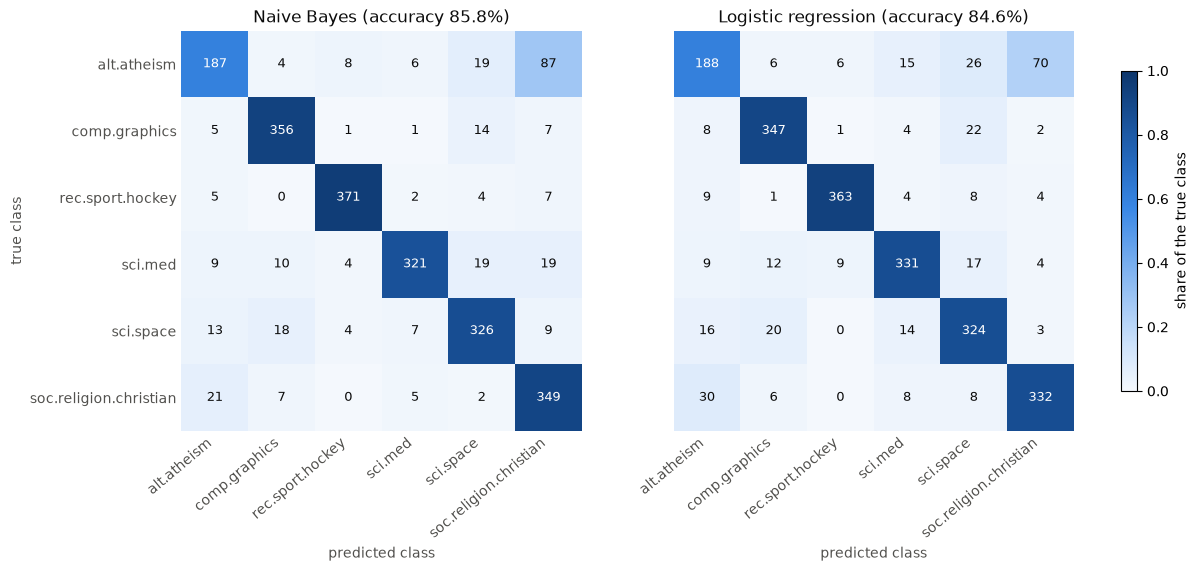

In [5]:
fig = plot_confusion_matrices(confusion_matrices(models, docs_test, y_test, len(class_names)), class_names)
plt.show()

In [6]:
informative_features(models, class_names, top_n=8)

,Naive Bayes,Logistic regression
class,,
alt.atheism,"islam, atheism, ico, bobb, beauchain, sank, mo...","islam, religion, moral, atheist, atheism, dele..."
comp.graphics,"graphic, vga, polygon, pov, tiff, cview, vesa,...","graphic, imag, file, comput, code, use, packag..."
rec.sport.hockey,"hockey, playoff, nhl, detroit, coach, espn, br...","game, team, hockey, play, player, playoff, sea..."
sci.med,"geb, chastiti, jxp, cadr, dsl, surrend, intell...","medic, doctor, msg, diseas, patient, treatment..."
sci.space,"shuttl, spacecraft, orbit, lunar, launch, moon...","space, orbit, launch, nasa, moon, spacecraft, ..."
soc.religion.christian,"christ, scriptur, bibl, jesus, ceremoni, churc...","christian, god, church, jesus, christ, sin, lo..."


**Observations**

In the example post, raw counts are led by function words ("the", "of", "a"), while TF-IDF favours rare names and specific terms such as "lunar" that set the post apart.

Naïve Bayes is slightly better than logistic regression (test macro-F1 0.85 vs. 0.84), a gap about the size of the spread across cross-validation folds, so the two models are practically on par. Hockey and graphics are the easiest classes. The main error is atheism posts predicted as Christianity: both groups discuss God and the Bible in the same words, and a bag of words captures the topic, not the writer's position.

Logistic regression's top features are general topic words (doctor, patient, team, game), while Naïve Bayes favours rare terms found in only one class. All eight `sci.med` terms of Naïve Bayes come from one frequent poster's e-mail signature, missed by the footer removal, so the model partly learns who wrote a post rather than its topic.

## Problem 5: word2vec on 20 Newsgroups vs. pretrained GloVe

**Approach.**

- **word2vec** (gensim, skip-gram with negative sampling): 100 dimensions, window 5, 5 negative samples, words seen at least 5 times, 5 epochs. Seed 0 and a single worker thread make training reproducible. It is trained on all 18,846 posts of 20 Newsgroups, because the six-group training set of Problem 4 is too small to learn useful embeddings. Tokens are lower-cased words as in Problem 4, but stop words are kept and nothing is stemmed, so queries and analogies use real words.
- **GloVe:** the pretrained `glove-wiki-gigaword-100` vectors (100 dimensions, 400k words, trained on about 6 billion tokens of Wikipedia and news).
- **Nearest neighbours** by cosine similarity for five query words, one per family of newsgroups: mouse, hockey, space, god, car.
- **Analogies:** the Google analogy test set (19,544 questions *a : b :: c : ?*, semantic and grammatical). The answer is the word closest to $b - a + c$, excluding the three input words. A model cannot answer a question that contains a word it has never seen, so we report each model's coverage separately and compare accuracy only on the questions both models cover.

In [7]:
from src.data import load_analogy_questions, load_glove, load_newsgroups
from src.embeddings import analogy_examples, analogy_summary, neighbours_table, train_word2vec
from src.preprocessing import sentences_for_embeddings

sentences = sentences_for_embeddings(load_newsgroups("all", categories=None).texts)
w2v = train_word2vec(sentences, random_state=0)
glove = load_glove()
embeddings = {"word2vec (20NG)": w2v.wv, "GloVe (6B)": glove}
print(f"word2vec: {sum(map(len, sentences)):,} training tokens, vocabulary of {len(w2v.wv):,} words")
print(f"GloVe:    vocabulary of {len(glove):,} words")

word2vec: 3,611,480 training tokens, vocabulary of 26,770 words
GloVe:    vocabulary of 400,000 words


In [8]:
neighbours_table(embeddings, ("mouse", "hockey", "space", "god", "car"), topn=5)

,word2vec (20NG),GloVe (6B)
query,,
mouse,"button (0.74), keyboard (0.74), smartdrv (0.73...","cat (0.69), rabbit (0.69), monkey (0.68), mice..."
hockey,"nhl (0.79), regulars (0.77), playoff (0.76), b...","basketball (0.80), football (0.78), nhl (0.76)..."
space,"shuttle (0.76), hubble (0.68), planetary (0.66...","nasa (0.70), spaces (0.69), shuttle (0.68), ea..."
god,"christ (0.85), god's (0.85), spirit (0.83), fa...","divine (0.79), christ (0.78), heaven (0.77), a..."
car,"bike (0.80), nissan (0.79), tire (0.77), tires...","vehicle (0.86), truck (0.86), cars (0.84), dri..."


In [9]:
examples = (
    ("man", "king", "woman", "queen"),           # gender
    ("france", "paris", "germany", "berlin"),    # country - capital
    ("big", "bigger", "small", "smaller"),       # comparative
    ("walk", "walking", "swim", "swimming"),     # present participle
    ("walk", "walked", "run", "ran"),            # irregular past tense
    ("hockey", "nhl", "basketball", "nba"),      # domain: sports leagues
    ("microsoft", "windows", "apple", "mac"),    # polysemous word
)
analogy_examples(embeddings, examples, topn=1)

,expected,word2vec (20NG),GloVe (6B)
analogy,,,
man : king :: woman : ?,queen,testified,queen ✓
france : paris :: germany : ?,berlin,salonica,berlin ✓
big : bigger :: small : ?,smaller,smaller ✓,larger
walk : walking :: swim : ?,swimming,gaz,swimming ✓
walk : walked :: run : ?,ran,ran ✓,went
hockey : nhl :: basketball : ?,nba,a's,nba ✓
microsoft : windows :: apple : ?,mac,monitor,window


GloVe solves the semantic relations (gender, capital cities, sports leagues) that word2vec misses, most likely because words such as *queen*, *berlin* or *nba* are rare in the posts. word2vec does better on some frequent grammatical patterns and here even beats GloVe, which answers *larger* instead of *smaller* and *went* instead of *ran*: it picks a word close in meaning over the right grammatical form. Both models fail on the polysemous *windows*: GloVe reads it as a house window, word2vec answers *monitor*. The examples are hand-picked to show different behaviours; the benchmark below measures the overall gap.

In [10]:
questions = load_analogy_questions()
summary = analogy_summary(embeddings, questions)
print(f"{summary.attrs['n_shared']:,} of {len(questions):,} questions are covered by both models")
summary.round(3)

9,443 of 19,544 questions are covered by both models


,coverage (all questions),"accuracy, semantic (shared)","accuracy, syntactic (shared)","accuracy, all (shared)"
model,,,,
word2vec (20NG),0.483,0.070,0.094,0.089
GloVe (6B),0.997,0.531,0.628,0.608


**Observations**

The neighbours show how strongly an embedding reflects its corpus. In the newsgroups *mouse* is an input device (button, keyboard, trackball), in GloVe an animal (cat, rabbit, monkey), and the 20NG neighbours of *car* come from car forums (nissan, tires, garage). Each word has a single vector, so the dominant sense in the corpus wins.

On the benchmark GloVe is far stronger: on the shared questions it is correct about 61% of the time against 9% for word2vec, which can attempt only half of the test set because many capitals and word forms are rare or missing in the posts.

Corpus size (3.6 million vs. about 6 billion tokens) and domain are plausible reasons for the gap, but this comparison cannot separate them from the different training methods. Vectors of rare words are unreliable.

## Problem 6: Social bias in the embeddings

**Probes.** We apply three probes to both embeddings from Problem 5.

- **WEAT** (Word Embedding Association Test; Caliskan et al., 2017) measures whether two groups of target words (e.g. male and female names) differ in how close they are, on average, to two groups of attribute words (e.g. career and family words). The effect size $d$ is a standardised difference ($|d| \ge 0.8$ counts as large), and the p-value comes from a permutation test that re-splits the target words at random. We run two gender tests and a non-social control (flowers vs. insects with pleasant vs. unpleasant words) that a reliable embedding should pass.
- **Gender direction:** the average difference between the vectors of eight male–female pairs (he–she, man–woman, father–mother, ...). The cosine between an occupation and this direction shows whether the occupation lies closer to the male (positive) or the female (negative) words.
- **Gendered analogies** such as *man : doctor :: woman : ?*, answered as in Problem 5. The standard protocol never returns an input word, so for two of them we also show the answer when the inputs are allowed.

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

from src.bias import GENDER_ANALOGIES, WEAT_TESTS, gendered_analogies, occupation_projection, weat_table
from src.plotting import plot_gender_projection

# embeddings come from Problem 5. The first three tests: the control, names vs. career/family,
# math/arts vs. male/female terms.
weat_table(embeddings, tests=list(WEAT_TESTS)[:3], random_state=0)

word2vec (20NG)            \
                                                                 d         p   
test                                                                           
WEAT 1: flowers vs. insects / pleasant vs. unpl...        0.522594  0.182401   
WEAT 6: male vs. female names / career vs. family         0.966978  0.026573   
WEAT 7: math vs. arts / male vs. female terms             1.495063  0.001665   

                                                   GloVe (6B)            
                                                            d         p  
test                                                                     
WEAT 1: flowers vs. insects / pleasant vs. unpl...   1.169293  0.000020  
WEAT 6: male vs. female names / career vs. family    1.717767  0.000078  
WEAT 7: math vs. arts / male vs. female terms        1.281220  0.002253

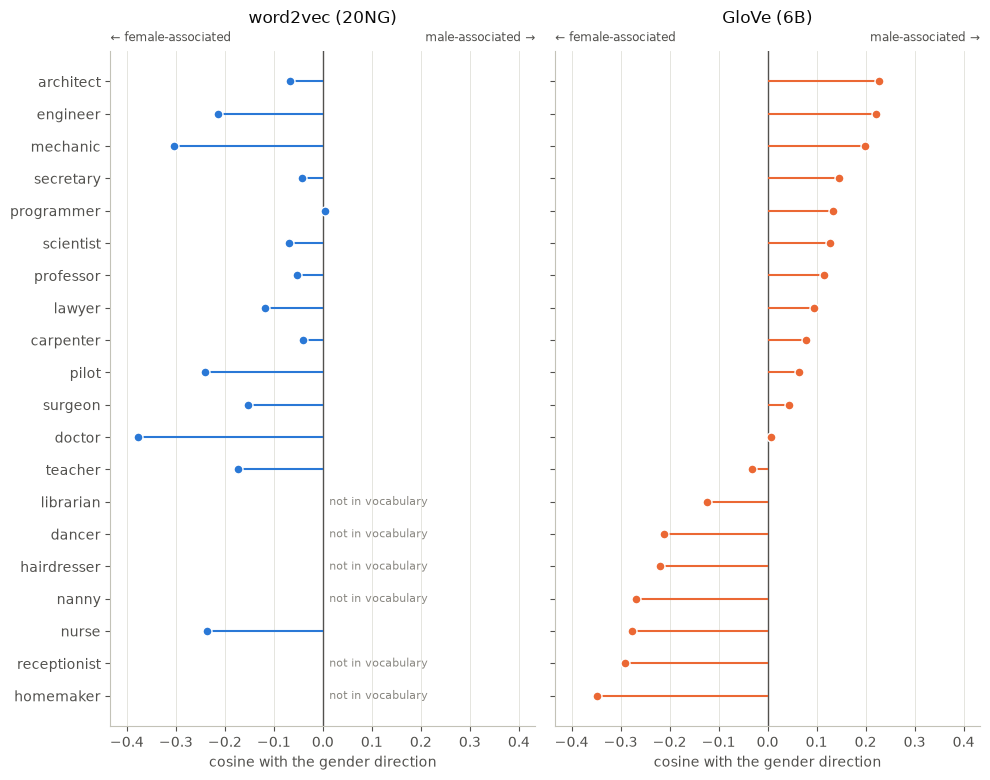

In [12]:
fig = plot_gender_projection(occupation_projection(embeddings))
plt.show()

Each point is the cosine between an occupation and the gender direction. In GloVe, domestic and care jobs (homemaker, receptionist, nurse, nanny) sit at the female end and technical and building trades (architect, engineer, mechanic) at the male end, while doctor and teacher lie close to zero. word2vec lacks six of the words and puts almost all the others on the female side without a clear order, so its direction is poorly estimated. These are associations learned from text, not properties of the jobs or evidence about who actually does them.

In [13]:
gendered_analogies(embeddings, GENDER_ANALOGIES)

,word2vec (20NG),GloVe (6B)
analogy,,
man : doctor :: woman : ?,she,nurse
man : engineer :: woman : ?,employee,technician
man : scientist :: woman : ?,distinguished,researcher
man : boss :: woman : ?,grandmother,bosses
man : strong :: woman : ?,weak,stronger
woman : nurse :: man : ?,essays,doctor


In [14]:
# The same two analogies with the input words excluded (standard) and allowed as answers.
caveat = (("man", "doctor", "woman"), ("woman", "nurse", "man"))
pd.concat(
    {
        "inputs excluded (standard)": gendered_analogies(embeddings, caveat),
        "inputs allowed": gendered_analogies(embeddings, caveat, allow_inputs=True),
    },
    axis=1,
)

inputs excluded (standard)             \
                                     word2vec (20NG) GloVe (6B)   
analogy                                                           
man : doctor :: woman : ?                        she      nurse   
woman : nurse :: man : ?                      essays     doctor   

                           inputs allowed             
                          word2vec (20NG) GloVe (6B)  
analogy                                               
man : doctor :: woman : ?          doctor     doctor  
woman : nurse :: man : ?           essays      nurse

Some GloVe answers follow occupational stereotypes (*doctor → nurse*, *engineer → technician*, and in reverse *nurse → doctor*), but others do not: *scientist* and *boss* map to gender-neutral words. word2vec mostly returns unrelated or gender words (*she*, *grandmother*), apart from the traditional *strong → weak*. Allowing the input words turns the GloVe answers back into *doctor* and *nurse*: the occupation itself is the closest word, and the stereotyped answer wins only because the protocol forbids it. Analogy outputs therefore reflect both the embedding and the evaluation procedure, and single examples are not proof of bias.

### Discussion

Across the three probes, GloVe encodes consistent gender stereotypes. WEAT associates male names with career words and mathematics with male terms, the gender direction separates care and domestic occupations from technical trades, and some analogies reproduce the same split (*doctor → nurse*) while others stay neutral (*scientist → researcher*). The probes also have clear limits: each relies on short, hand-picked word lists, and analogy results depend on the evaluation protocol, since a stereotyped answer can win only because the input word is excluded. The 20 Newsgroups word2vec points in the same direction on WEAT but fails the non-social control and orders occupations erratically. With 3.6 million tokens its estimates are too noisy to trust, although they are not necessarily pure noise. Because embeddings store which words co-occur in their training text, these associations pass into systems built on them: a CV-screening model using such vectors could score applicants for engineering roles lower when their CVs contain female-associated words. Bias should therefore be measured in the final application and mitigated where it affects decisions.